# 06 Spark Structured Streaming, Bronze to Silver (E5, small)

`python -m etl.stream_sss`. A producer process appends captured lines to a demo Delta table at a fixed rate; a streaming query (trigger 1 s, `foreachBatch`) parses them and MERGEs them into a demo Silver table. Latency = MERGE commit time - produced_at. Runs on one laptop (local[4]).

In [1]:
import json, os, sys
from pathlib import Path
REPO = Path.cwd().resolve().parents[1] if Path.cwd().name == 'final' else Path.cwd()
sys.path.insert(0, str(REPO))
os.environ.setdefault('TRUTHLAG_HW2_DIR', str(REPO / 'ec-hw2'))
import pandas as pd
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)
from deltalake import DeltaTable
LAKE = REPO / 'data' / 'lake'
RUNS = LAKE / '_runs'
def run(name): return json.loads((RUNS / name).read_text())
def table(name, version=None, columns=None):
    return DeltaTable(str(LAKE / name), version=version).to_pandas(columns=columns)
def history(name, n=10):
    h = DeltaTable(str(LAKE / name)).history(n)
    return pd.DataFrame([{k: e.get(k) for k in ('version', 'operation', 'step', 'as_of', 'snapshot', 'rows')} for e in h])
s = run('stream_sss.json')
pd.DataFrame(s['rates'])[['target_rate_eps', 'events', 'micro_batches', 'throughput_eps', 'latency_p50_s', 'latency_p95_s', 'latency_max_s', 'mean_batch_rows', 'mean_batch_merge_s']]

,target_rate_eps,events,micro_batches,throughput_eps,latency_p50_s,latency_p95_s,latency_max_s,mean_batch_rows,mean_batch_merge_s
0,1000,30000,24,981.8,1.897,2.901,3.045,1250.0,1.229
1,2500,75000,22,2428.0,2.046,3.303,3.808,3409.1,1.255
2,5000,150000,22,4717.6,2.177,3.406,3.791,6818.2,1.291
3,10000,300000,19,9391.2,2.544,4.066,4.160,15789.5,1.562
4,20000,599997,16,18275.9,3.483,5.216,5.492,37499.8,1.925


In [2]:
s['drain']

{'run': 'drain (availableNow, 5 files per batch)',
 'events': 500000,
 'micro_batches': 10,
 'wall_s': 30.1,
 'throughput_eps': 16614.6,
 'mean_batch_rows': 50000.0,
 'mean_batch_merge_s': 2.015,
 'parity_with_batch_silver': {'stream_rows': 500000,
  'only_stream': 0,
  'differing': 0}}

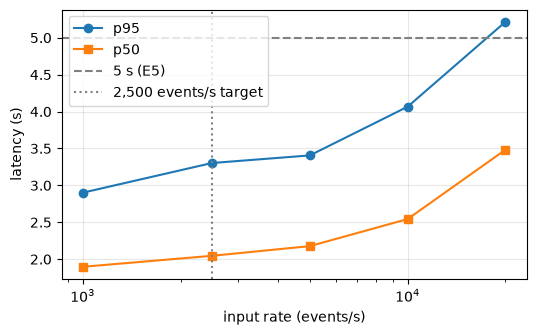

In [3]:
import matplotlib.pyplot as plt
r = pd.DataFrame(s['rates'])
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(r.target_rate_eps, r.latency_p95_s, 'o-', label='p95')
ax.plot(r.target_rate_eps, r.latency_p50_s, 's-', label='p50')
ax.axhline(5, color='grey', ls='--', label='5 s (E5)')
ax.axvline(2500, color='grey', ls=':', label='2,500 events/s target')
ax.set_xscale('log'); ax.set_xlabel('input rate (events/s)'); ax.set_ylabel('latency (s)'); ax.legend(); ax.grid(alpha=.3)